In [31]:
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
import math
import numpy as np
import pandas as pd
from pathlib import Path

from mpmath.calculus import extrapolation
from torch.ao.nn.quantized.functional import threshold
from scaling.utils import functional_form_L0, fit_parametric_form, functional_form_L0_max, fit_linear_model, sigmoid_functional_form
from scaling.utils import double_sigmoid_functional_form
from itertools import product

sns.set_style("white")

# Data Loading

In [32]:
base_figure_path = Path.cwd() / "figures" / "nanotabpfn"
base_figure_path.mkdir(parents=True, exist_ok=True)
base_output_path = Path.cwd() / "output" / "nanotabpfn"
base_output_path.mkdir(parents=True, exist_ok=True)


df = pd.read_csv("../data/nanotabpfn_data_preprocessed.csv",index_col=[0, 1])
config_columns = [col for col in df.columns if col.startswith('config/')]
print("config columns: ", config_columns)
loss_columns = ['real_data/nll', 'real_data/roc_auc', 'val/val_loss', 'val/small/val_loss', 'val/medium/val_loss']
loss_columns_extended = loss_columns + ['real_data/accuracy', 'real_data/balanced_accuracy']

print(f"{df['total_flops_rounded'].min():.2e}", df['total_flops_rounded'].max())

# FILTER_FLOPS_MAX = 1.00000000e+16 * 1.05
FILTER_FLOPS_MAX = df['total_flops_rounded'].max() * 0.105
# FILTER_FLOPS_MIN = 1.00000000e+11 * 0.95
FILTER_FLOPS_MIN = df['total_flops_rounded'].min() * 0.95
extrapolation_df = df[FILTER_FLOPS_MAX < df['total_flops_rounded']]
df = df[(FILTER_FLOPS_MAX > df['total_flops_rounded']) & (df['total_flops_rounded'] > FILTER_FLOPS_MIN)]

print(f"{FILTER_FLOPS_MIN:.2e}", f"{FILTER_FLOPS_MAX:.2e}")

config columns:  ['config/effective_batch_size', 'config/lr', 'config/max_features', 'config/model_config.embedding_size', 'config/model_config.num_attention_heads', 'config/model_config.num_layers', 'config/num_datapoints_max', 'config/num_flops_training', 'config/weight_decay']
1.78e+11 1e+17
1.69e+11 1.05e+16


In [33]:
df.head()

total_flops_rounded  real_data/nll  real_data/roc_auc  \
run grid_idx                                                          
0   1                1.778279e+11       0.803121           0.477613   
    2                3.162278e+11       0.749464           0.474233   
    3                5.623413e+11       0.703441           0.487485   
    4                1.000000e+12       0.664073           0.543674   
    5                1.778279e+12       0.632214           0.562025   

              real_data/accuracy  real_data/balanced_accuracy  val/val_loss  \
run grid_idx                                                                  
0   1                   0.667195                     0.439873      1.502620   
    2                   0.670778                     0.436306      1.298415   
    3                   0.665492                     0.435976      1.186846   
    4                   0.697292                     0.436465      1.123981   
    5                   0.727915                     0.437583      1.073899   

              val/small/val_loss  val/medium/val_loss  \
run grid_idx                                            
0   1                   1.503669             1.501571   
    2                   1.297584             1.299245   
    3                   1.185688             1.188004   
    4                   1.123471             1.124492   
    5                   1.073836             1.073962   

              real_data/Bank_Customer_Churn/accuracy  \
run grid_idx                                           
0   1                                         0.7963   
    2                                         0.7963   
    3                                         0.7963   
    4                                         0.7963   
    5                                         0.7963   

              real_data/Bank_Customer_Churn/balanced_accuracy  ...  config/lr  \
run grid_idx                                                   ...              
0   1                                                     0.5  ...    0.00005   
    2                                                     0.5  ...    0.00005   
    3                                                     0.5  ...    0.00005   
    4                                                     0.5  ...    0.00005   
    5                                                     0.5  ...    0.00005   

              config/max_features  config/model_config.embedding_size  \
run grid_idx                                                            
0   1                           2                                  16   
    2                           2                                  16   
    3                           2                                  16   
    4                           2                                  16   
    5                           2                                  16   

              config/model_config.num_attention_heads  \
run grid_idx                                            
0   1                                               2   
    2                                               2   
    3                                               2   
    4                                               2   
    5                                               2   

              config/model_config.num_layers  config/num_datapoints_max  \
run grid_idx                                                              
0   1                                      1                        100   
    2                                      1                        100   
    3                                      1                        100   
    4                                      1                        100   
    5                                      1                        100   

              config/num_flops_training  config/weight_decay  parameters  \
run grid_idx                                                               
0   1      

In [34]:
for col in df.columns:
    if not (len(df[col].unique()) > 1):
        # prints columns with only one unique value
        print(col, len(df[col].unique()))

# Scaling Trends

In [35]:
def get_pareto_frontier(
        df: pd.DataFrame,
        x_name="flops",
        y_name="Validation Loss",
        minimization=True,
) -> pd.DataFrame:
    """ Function to compute Pareto over FLOPs.
    """
    # NOTE: strict assumption here that x_name is maximized and y_name is minimized
    df_copy = df.copy()
    if not minimization:
        df_copy[y_name] = - df_copy[y_name]
    df_sorted = df_copy.sort_values(by=[x_name, y_name], ascending=[True, True])
    df_sorted = df_sorted.drop_duplicates(subset=[x_name], keep="first")
    pareto_points = []
    min_loss_so_far = float('inf')
    for _, row in df_sorted.iterrows():
        if row[y_name] < min_loss_so_far:
            pareto_points.append(row)
            min_loss_so_far = row[y_name]

    df_copy = pd.DataFrame(pareto_points)
    if not minimization:
        df_copy[y_name] = - df_copy[y_name]
    return df_copy


def get_optimal_values(
        df: pd.DataFrame,
        x_name="flops",
        y_name="Validation Loss",
        minimization=True,
) -> pd.DataFrame:
    df_copy = df.copy()
    if not minimization:
        df_copy[y_name] = - df_copy[y_name]
    df_sorted = df_copy.sort_values(by=[x_name, y_name], ascending=[True, True])
    df_optimal = df_sorted.drop_duplicates(subset=[x_name], keep="first")
    if not minimization:
        df_optimal[y_name] = - df_optimal[y_name]
    return df_optimal

In [36]:
FLOP_VALUES = np.array([
    1.00000000e+11, 1.77827941e+11, 3.16227766e+11, 5.62341325e+11,
    1.00000000e+12, 1.77827941e+12, 3.16227766e+12, 5.62341325e+12,
    1.00000000e+13, 1.77827941e+13, 3.16227766e+13, 5.62341325e+13,
    1.00000000e+14, 1.77827941e+14, 3.16227766e+14, 5.62341325e+14,
    1.00000000e+15, 1.77827941e+15, 3.16227766e+15, 5.62341325e+15,
    1.00000000e+16, 1.77827941e+16, 3.16227766e+16, 5.62341325e+16,
    1.00000000e+17, 1.77827941e+17, 3.16227766e+17, 5.62341325e+17,
    1.00000000e+18, 1.77827941e+18, 3.16227766e+18, 5.62341325e+18,
    1.00000000e+19
])

In [37]:
# Add additional columns to analyse
df['prior_max_cells'] = df['config/max_features'] * df['config/num_datapoints_max']
df['aspect_ratio'] = df['config/model_config.embedding_size'] / df['config/model_config.num_layers']
df['prior_ratio'] = df['config/num_datapoints_max'] / df['config/max_features']

flops_column = 'total_flops_rounded'

trend_columns = config_columns + ["parameters", "total_cells"] + [
    "prior_max_cells", "aspect_ratio", "prior_ratio"
]

# --- Consistent styling per metric ------------------------------------------------
# The two metric families are encoded twice on purpose: warm hues + solid lines for the
# metrics measured on *real data*, cool hues + dashed lines for the metrics measured on
# the *prior validation* sets. The grouping therefore survives greyscale printing and
# colour-vision deficiency, while the hue still identifies the individual metric.
# (Palette checked for lightness band, chroma floor, and CVD / normal-vision separation.)


LOSS_FAMILIES = {
    "real_data": "Real Data",
    "val": "In-Prior validation",
}

# The fits within one family come out almost coincident, so the line widths taper in
# drawing order: the later, thinner line stays visible as a core inside the earlier one.
LOSS_STYLES = {
    'real_data/nll':       {"color": "#d1121f", "linestyle": "-",  "linewidth": 4.5, "label": "NLL"},
    'real_data/roc_auc':   {"color": "#e07b00", "linestyle": "-",  "linewidth": 1.8, "label": "ROC AUC"},
    'val/val_loss':        {"color": "#2a78d6", "linestyle": "--", "linewidth": 5.0, "label": "val loss"},
    'val/small/val_loss':  {"color": "#1baf7a", "linestyle": "--", "linewidth": 3.0, "label": "val loss (small)"},
    'val/medium/val_loss': {"color": "#4a3aa7", "linestyle": "--", "linewidth": 1.4, "label": "val loss (medium)"},
}

def loss_family(loss_column):
    """'real_data' or 'val' -- the family a loss column belongs to."""
    return loss_column.split("/")[0]

def loss_style(loss_column, **overrides):
    """Style kwargs for a loss column, e.g. ax.plot(x, y, **loss_style(col, alpha=0.8))."""
    style = dict(LOSS_STYLES[loss_column])
    style.update(overrides)
    return style

def family_legends(ax, columns=None, locs=("upper left", "lower right"), **legend_kwargs):
    """Draw one legend box per metric family so the real-data / prior-val split is explicit."""
    columns = loss_columns if columns is None else columns
    kwargs = dict(fontsize="x-small", title_fontsize="small", framealpha=0.9)
    kwargs.update(legend_kwargs)
    for (family, title), loc in zip(LOSS_FAMILIES.items(), locs):
        handles = [
            Line2D([], [], **loss_style(col, linewidth=min(LOSS_STYLES[col]["linewidth"], 3.0)))
            for col in columns if loss_family(col) == family
        ]
        if not handles:
            continue
        ax.add_artist(ax.legend(handles=handles, title=title, loc=loc, **kwargs))

/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_29322/2028991924.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['prior_max_cells'] = df['config/max_features'] * df['config/num_datapoints_max']
/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_29322/2028991924.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['aspect_ratio'] = df['config/model_config.embedding_size'] / df['config/model_config.num_layers']
/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_29322/2028991924.py:4: Performance

In [38]:
extrapolation_df[flops_column].min(), df[flops_column].max()

(np.float64(1.77827941e+16), np.float64(1e+16))

# Fit scaling laws for the individual parts.

In [75]:
# # Scaling laws on loss for the different metrics
# param_names = {0: "L0", 1: "a", 2: "alpha"}

# initial_grid_min = [
#     [0, 0.1, 0.5],
#     [0.1, 1, 2, 5, 10, 50, 100],
#     [-1, -0.5, 0, 0.5, 1]
# ]
# bounds_min = [
#     (1e-6, 1),
#     (0, 100),
#     (-5, 5)
# ]

# initial_grid_max = [
#     [0, 1, 2, 4, 8],
#     [-30, -20, -10, -5, -2.5, -1, -0.5, 0],
#     [-2, -1, -0.5, -0.25, 0, 0.25, 0.5, 1, 2]
# ]

# initial_grid_sigmoid = [
#     [0.85, 0.9, 0.95, 0.99, 0.999],    # a_max   (ceiling)
#     [2, 4, 6, 8, 10, 12],              # log10(x0)  (midpoint)
#     [0.1, 0.3, 1.0, 3.0, 10.0],        # k       (steepness per decade)
#     [0.45, 0.5],                       # a_min   (floor)
# ]

# # Big-prior ROC AUC is S-shaped: a plateau, a sharp rise near 2e13 FLOPs, then a slow rise that levels off.
# # double_sigmoid_functional_form: a sharp logistic step plus a broad one, all parameters fitted.
# initial_grid_double_sigmoid = [
#     [0.45, 0.5],                       # a_min   (floor)
#     [0.15, 0.2],                       # h1      (height of the sharp step)
#     [13.3],                            # x1      (log10 FLOPs of the sharp step)
#     [5, 10],                           # k1      (steepness per decade)
#     [0.15, 0.25, 0.35],                # h2      (height of the broad step)
#     [12.5, 13.5, 14.5],                # x2      (log10 FLOPs of the broad step)
#     [0.3, 0.6, 1.0],                   # k2      (steepness per decade)
# ]
# bounds_double_sigmoid = [(0.3, 0.6), (0, 0.5), (12, 15), (0.5, 50), (0, 0.5), (10, 18), (0.01, 5)]

# bounds_max = [
#     (0, 10),
#     (-40, 0),
#     (-5, 5)
# ]

# # Load TabPFN Reference
# # tabpfn_tabarena_baseline = pd.read_csv("../data/summary_tabpfn.csv", index_col=0).loc["tabarena"]

# # LOSS_

# sns.set_context("talk")

# custom_metrics = ['val/val_loss', 'real_data/nll', 'real_data/roc_auc']

# save_path = base_figure_path / "pareto_fitting"
# save_path.mkdir(parents=True, exist_ok=True)

# n_cols = len(custom_metrics)
# fig, axes = plt.subplots(2, n_cols, layout='constrained', figsize=(5 * n_cols, 7), squeeze=False)

# for ax_prior in axes[1, 1:]:
#     ax_prior.sharex(axes[1, 0])
#     ax_prior.sharey(axes[1, 0])

# # for loss_idx, loss_column in enumerate(loss_columns_extended):
# for loss_idx, loss_column in enumerate(custom_metrics):
#     ax, ax_nd = axes[0, loss_idx], axes[1, loss_idx]

#     # if loss_column.split("/")[1] in tabpfn_tabarena_baseline.index:
#     #     ax.axhline(y=tabpfn_tabarena_baseline[loss_column.split("/")[1]])

#     maximization = "roc_auc" in loss_column or "accuracy" in loss_column
#     minimization = not maximization
#     pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)
#     # pareto_extrapolation = get_optimal_values(extrapolation_df, flops_column, loss_column, minimization=minimization)
#     pareto_extrapolation = get_pareto_frontier(extrapolation_df, flops_column, loss_column, minimization=minimization)

#     ax.scatter(pareto[flops_column], pareto[loss_column], marker='x')
#     ax.scatter(pareto_extrapolation[flops_column], pareto_extrapolation[loss_column], marker='x', color='red')

#     if True: #minimization:
#         initial_grid = initial_grid_min
#         bounds = None
#         func_form = functional_form_L0
#     else:
#         pass
#         initial_grid = initial_grid_max
#         bounds = bounds_max
#         func_form = functional_form_L0_max

#     X_data = pareto[flops_column].values
#     y_data = np.log(pareto[loss_column].values) if minimization else np.log(1-pareto[loss_column].values)

#     best_params, best_loss = fit_parametric_form(
#         func_form=func_form,
#         X_data=X_data,
#         y_data=y_data,
#         initial_grid=list(product(*initial_grid)),
#         bounds=bounds,
#         delta=1e-3,
#         use_scipy=True,
#     )
#     print(loss_column)
#     print(best_params)
#     print("irreducible loss: ", np.exp(best_params[0]) if minimization else 1-np.exp(best_params[0]))

#     # compute-optimal scaling of the Pareto points with FLOPs: N = A * C^a, D = B * C^b
#     for target in ["parameters", "total_cells"]:
#         s, i, r, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto[target]))
#         print(f"  {target:12s} = {np.exp(i):.3g} * FLOPs^{s:.4f}   R2={r**2:.3f}")

#     y_pred = func_form(FLOP_VALUES, best_params, return_log_loss=False)
#     y_pred = y_pred if minimization else 1-y_pred

#     ax.plot(
#         FLOP_VALUES[np.where(df[flops_column].max() >= FLOP_VALUES)[0]],
#         y_pred[np.where(df[flops_column].max() >= FLOP_VALUES)[0]],
#         linestyle="-",
#         color="black",
#         linewidth=1.5,
#     )
#     ax.plot(
#         FLOP_VALUES[np.where(extrapolation_df[flops_column].min() <= FLOP_VALUES)[0]],
#         y_pred[np.where(extrapolation_df[flops_column].min() <= FLOP_VALUES)[0]],
#         linestyle="--",
#         color="gray",
#     )
#     ax.set_xscale("log")
#     ax.set_xlabel("FLOPs")
#     ax.set_title(loss_column)
#     if minimization:
#         ax.set_yscale("log")

#     _cmap = "magma_r" if minimization else "magma"
#     _all_loss = np.concatenate([pareto[loss_column].values, pareto_extrapolation[loss_column].values])
#     _norm = dict(cmap=_cmap, vmin=_all_loss.min(), vmax=_all_loss.max())

#     sc = ax_nd.scatter(
#         pareto.parameters, pareto.total_cells,
#         c=pareto[loss_column], **_norm,
#     )
#     ax_nd.scatter(
#         pareto_extrapolation.parameters, pareto_extrapolation.total_cells,
#         c=pareto_extrapolation[loss_column], marker='x', **_norm,
#     )

#     fig.colorbar(sc, ax=ax_nd)
#     ax_nd.set_xscale("log")
#     ax_nd.set_yscale("log")
#     ax_nd.set_xlabel("Parameters")
#     if loss_idx == 0:
#         ax_nd.set_ylabel("Total Cells")

# fig.savefig(save_path / "pareto_fits_with_nd.pdf")
# print(f"Saving {save_path / 'pareto_fits_with_nd.pdf'}")

In [97]:
custom_metrics = ['val/val_loss', 'real_data/nll', 'real_data/roc_auc']
custom_labels = {
    'val/val_loss': 'Synthetic: Loss',
    'real_data/nll': 'Real: NLL',
    'real_data/roc_auc': 'Real: ROC AUC'
}

val/val_loss
[-0.53378822  0.95877302 -0.06795716]
irreducible loss:  0.5863794226024645
  parameters   = 0.0795 * FLOPs^0.3805   R2=0.901
  total_cells  = 13.7 * FLOPs^0.5435   R2=0.949
real_data/nll
[-12.76565684   1.15639217  -0.06124705]
irreducible loss:  2.857233111856262e-06
  parameters   = 5.58 * FLOPs^0.2523   R2=0.840
  total_cells  = 0.135 * FLOPs^0.6745   R2=0.973
real_data/roc_auc
[-2.16513947  4.67318025 -0.23267182]
irreducible loss:  0.885266068001738
  parameters   = 53.9 * FLOPs^0.1923   R2=0.668
  total_cells  = 0.0368 * FLOPs^0.7096   R2=0.962
Saving /Users/mallik/Documents/git_repos/EffingScaling/playground/figures/nanotabpfn/pareto_fitting/pareto_fits_with_nd.pdf


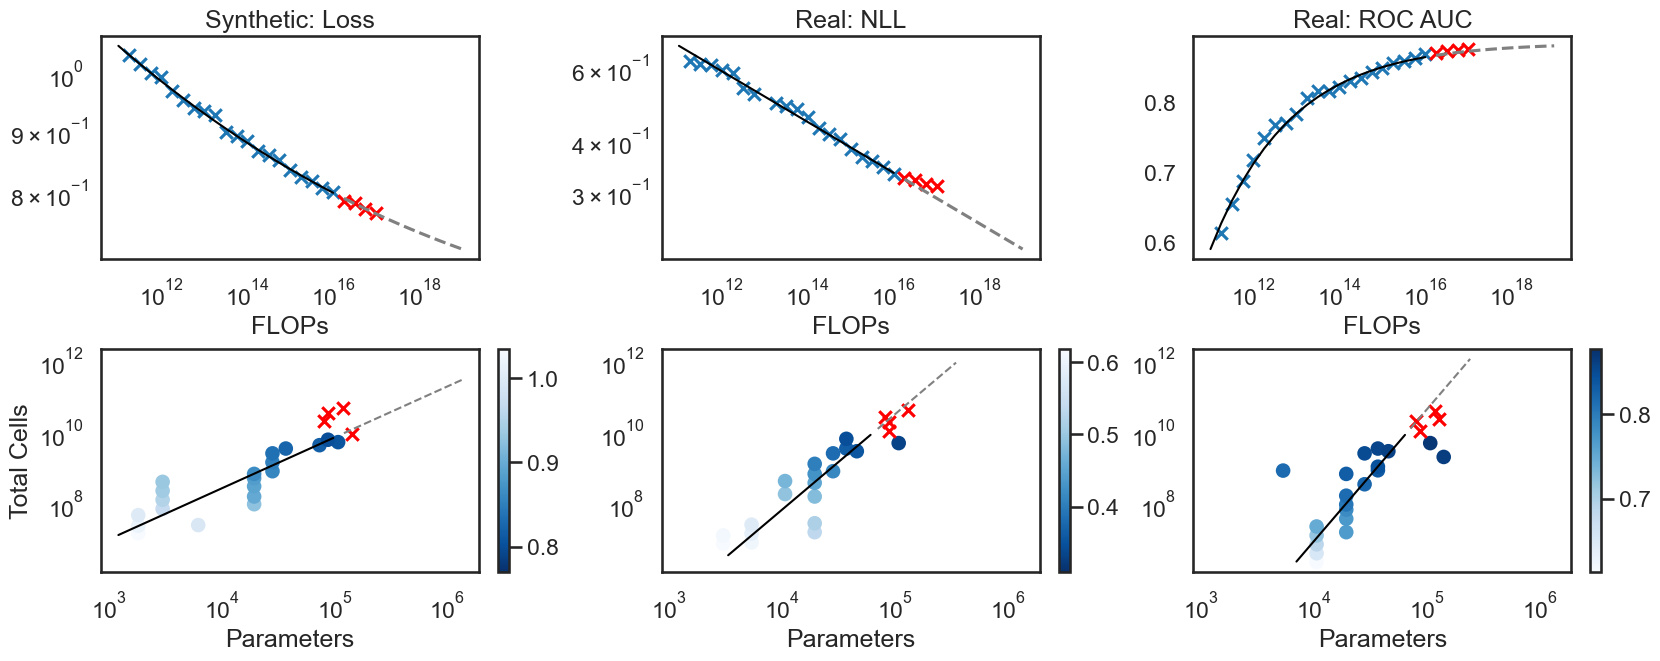

In [99]:
# Scaling laws on loss for the different metrics
param_names = {0: "L0", 1: "a", 2: "alpha"}

initial_grid_min = [
    [0, 0.1, 0.5],
    [0.1, 1, 2, 5, 10, 50, 100],
    [-1, -0.5, 0, 0.5, 1]
]
bounds_min = [
    (1e-6, 1),
    (0, 100),
    (-5, 5)
]

initial_grid_max = [
    [0, 1, 2, 4, 8],
    [-30, -20, -10, -5, -2.5, -1, -0.5, 0],
    [-2, -1, -0.5, -0.25, 0, 0.25, 0.5, 1, 2]
]

initial_grid_sigmoid = [
    [0.85, 0.9, 0.95, 0.99, 0.999],    # a_max   (ceiling)
    [2, 4, 6, 8, 10, 12],              # log10(x0)  (midpoint)
    [0.1, 0.3, 1.0, 3.0, 10.0],        # k       (steepness per decade)
    [0.45, 0.5],                       # a_min   (floor)
]

# Big-prior ROC AUC is S-shaped: a plateau, a sharp rise near 2e13 FLOPs, then a slow rise that levels off.
# double_sigmoid_functional_form: a sharp logistic step plus a broad one, all parameters fitted.
initial_grid_double_sigmoid = [
    [0.45, 0.5],                       # a_min   (floor)
    [0.15, 0.2],                       # h1      (height of the sharp step)
    [13.3],                            # x1      (log10 FLOPs of the sharp step)
    [5, 10],                           # k1      (steepness per decade)
    [0.15, 0.25, 0.35],                # h2      (height of the broad step)
    [12.5, 13.5, 14.5],                # x2      (log10 FLOPs of the broad step)
    [0.3, 0.6, 1.0],                   # k2      (steepness per decade)
]
bounds_double_sigmoid = [(0.3, 0.6), (0, 0.5), (12, 15), (0.5, 50), (0, 0.5), (10, 18), (0.01, 5)]

bounds_max = [
    (0, 10),
    (-40, 0),
    (-5, 5)
]

# Load TabPFN Reference
# tabpfn_tabarena_baseline = pd.read_csv("../data/summary_tabpfn.csv", index_col=0).loc["tabarena"]

# LOSS_

sns.set_context("talk")

save_path = base_figure_path / "pareto_fitting"
save_path.mkdir(parents=True, exist_ok=True)

n_cols = len(custom_metrics)
fig, axes = plt.subplots(2, n_cols, layout='constrained', figsize=(5.5 * n_cols, 6.5), squeeze=False)

for ax_prior in axes[1, 1:]:
    ax_prior.sharex(axes[1, 0])
    ax_prior.sharey(axes[1, 0])

# for loss_idx, loss_column in enumerate(loss_columns_extended):
for loss_idx, loss_column in enumerate(custom_metrics):
    ax, ax_nd = axes[0, loss_idx], axes[1, loss_idx]

    # if loss_column.split("/")[1] in tabpfn_tabarena_baseline.index:
    #     ax.axhline(y=tabpfn_tabarena_baseline[loss_column.split("/")[1]])

    maximization = "roc_auc" in loss_column or "accuracy" in loss_column
    minimization = not maximization
    pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)
    # pareto_extrapolation = get_optimal_values(extrapolation_df, flops_column, loss_column, minimization=minimization)
    pareto_extrapolation = get_pareto_frontier(extrapolation_df, flops_column, loss_column, minimization=minimization)

    ax.scatter(pareto[flops_column], pareto[loss_column], marker='x')
    ax.scatter(pareto_extrapolation[flops_column], pareto_extrapolation[loss_column], marker='x', color='red')

    if True: #minimization:
        initial_grid = initial_grid_min
        bounds = None
        func_form = functional_form_L0
    else:
        pass
        initial_grid = initial_grid_max
        bounds = bounds_max
        func_form = functional_form_L0_max

    X_data = pareto[flops_column].values
    y_data = np.log(pareto[loss_column].values) if minimization else np.log(1-pareto[loss_column].values)

    best_params, best_loss = fit_parametric_form(
        func_form=func_form,
        X_data=X_data,
        y_data=y_data,
        initial_grid=list(product(*initial_grid)),
        bounds=bounds,
        delta=1e-3,
        use_scipy=True,
    )
    print(loss_column)
    print(best_params)
    print("irreducible loss: ", np.exp(best_params[0]) if minimization else 1-np.exp(best_params[0]))

    # compute-optimal scaling of the Pareto points with FLOPs: N = A * C^a, D = B * C^b
    nd_fits = {}
    for target in ["parameters", "total_cells"]:
        s, i, r, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto[target]))
        nd_fits[target] = (np.exp(i), s)
        print(f"  {target:12s} = {np.exp(i):.3g} * FLOPs^{s:.4f}   R2={r**2:.3f}")
    # predicted compute-optimal (N, D) at each FLOP level, in FLOP_VALUES order
    N_pred = nd_fits["parameters"][0] * FLOP_VALUES ** nd_fits["parameters"][1]
    D_pred = nd_fits["total_cells"][0] * FLOP_VALUES ** nd_fits["total_cells"][1]

    y_pred = func_form(FLOP_VALUES, best_params, return_log_loss=False)
    y_pred = y_pred if minimization else 1-y_pred

    ax.plot(
        FLOP_VALUES[np.where(df[flops_column].max() >= FLOP_VALUES)[0]],
        y_pred[np.where(df[flops_column].max() >= FLOP_VALUES)[0]],
        linestyle="-",
        color="black",
        linewidth=1.5,
    )
    ax.plot(
        FLOP_VALUES[np.where(extrapolation_df[flops_column].min() <= FLOP_VALUES)[0]],
        y_pred[np.where(extrapolation_df[flops_column].min() <= FLOP_VALUES)[0]],
        linestyle="--",
        color="gray",
    )
    ax.set_xscale("log")
    ax.set_xlabel("FLOPs")
    # ax.set_title(loss_column)
    ax.set_title(custom_labels.get(loss_column, loss_column))
    if minimization:
        ax.set_yscale("log")

    _cmap = "magma_r" if minimization else "magma"
    __cmap = "Blues"  # "magma"
    _cmap = f"{__cmap}_r" if minimization else __cmap
    _all_loss = np.concatenate([pareto[loss_column].values, pareto_extrapolation[loss_column].values])
    _norm = dict(cmap=_cmap, vmin=_all_loss.min(), vmax=_all_loss.max())

    sc = ax_nd.scatter(
        pareto.parameters, pareto.total_cells,
        c=pareto[loss_column], **_norm,
    )
    ax_nd.scatter(
        pareto_extrapolation.parameters, pareto_extrapolation.total_cells, marker='x',
        c="red",
        # c=pareto_extrapolation[loss_column],  **_norm,
    )

    in_range = FLOP_VALUES <= pareto[flops_column].max()
    ax_nd.plot(N_pred[in_range], D_pred[in_range], linestyle="-", color="black", linewidth=1.5)
    ax_nd.plot(N_pred[~in_range], D_pred[~in_range], linestyle="--", color="gray", linewidth=1.5)

    fig.colorbar(sc, ax=ax_nd)
    ax_nd.set_xscale("log")
    ax_nd.set_yscale("log")
    ax_nd.set_xlabel("Parameters")
    if loss_idx == 0:
        ax_nd.set_ylabel("Total Cells")

fig.savefig(save_path / "pareto_fits_with_nd.pdf")
print(f"Saving {save_path / 'pareto_fits_with_nd.pdf'}")

Saving /Users/mallik/Documents/git_repos/EffingScaling/playground/figures/nanotabpfn/pareto_fitting/compute_optimal_nd_paths.pdf


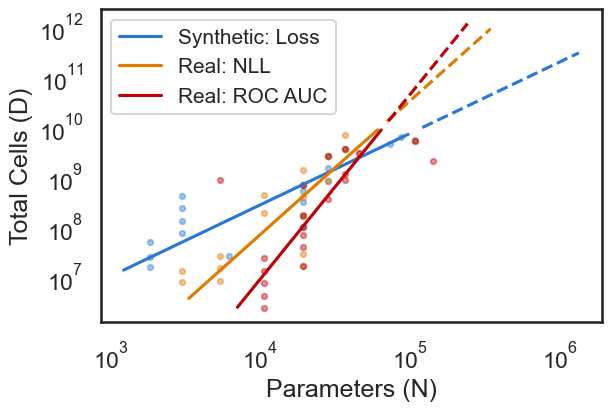

In [100]:
# Compute-optimal (N, D) path per metric: power laws N = A * C^a, D = B * C^b fitted on each Pareto front,
# evaluated at FLOP_VALUES and drawn in the (Parameters, Total Cells) plane
nd_metrics = {
    'val/val_loss':      {"color": "#2a78d6", "label": "Synthetic: Loss"},
    'real_data/nll':     {"color": "#e07b00", "label": "Real: NLL"},
    'real_data/roc_auc': {"color": "#bf0006", "label": "Real: ROC AUC"},
}

fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for loss_column, style in nd_metrics.items():
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)

    fits = {}
    for target in ["parameters", "total_cells"]:
        s, i, _, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto[target]))
        fits[target] = (np.exp(i), s)
    N_pred = fits["parameters"][0] * FLOP_VALUES ** fits["parameters"][1]
    D_pred = fits["total_cells"][0] * FLOP_VALUES ** fits["total_cells"][1]

    in_range = FLOP_VALUES <= pareto[flops_column].max()
    ax.scatter(pareto["parameters"], pareto["total_cells"], color=style["color"], alpha=0.4, s=15)
    ax.plot(N_pred[in_range], D_pred[in_range], linestyle="-", color=style["color"], label=f"{style['label']}")
    ax.plot(N_pred[~in_range], D_pred[~in_range], linestyle="--", color=style["color"])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Parameters (N)")
ax.set_ylabel("Total Cells (D)")
ax.legend(fontsize="small")

fig.savefig(save_path / "compute_optimal_nd_paths.pdf")
print(f"Saving {save_path / 'compute_optimal_nd_paths.pdf'}")


Saving /Users/mallik/Documents/git_repos/EffingScaling/playground/figures/nanotabpfn/prior_ablation/compute_optimal_flops_vs_parameters.pdf


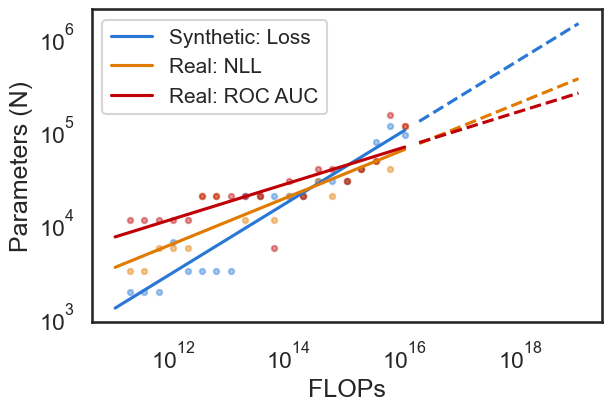

In [104]:
# Compute-optimal Parameters (N) vs FLOPs per metric: power law parameters = A * C^a fitted on each Pareto front,
# evaluated at FLOP_VALUES; solid within the front's FLOP range, dashed beyond
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for loss_column, style in nd_metrics.items():
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)

    s, i, r, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto["parameters"]))
    y_pred = np.exp(i) * FLOP_VALUES ** s

    in_range = FLOP_VALUES <= pareto[flops_column].max()
    ax.scatter(pareto[flops_column], pareto["parameters"], color=style["color"], alpha=0.4, s=15)
    ax.plot(FLOP_VALUES[in_range], y_pred[in_range], linestyle="-", color=style["color"],
            label=f"{style['label']}")#: $\\propto C^{{{s:.2f}}}$")
    ax.plot(FLOP_VALUES[~in_range], y_pred[~in_range], linestyle="--", color=style["color"])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("FLOPs")
ax.set_ylabel("Parameters (N)")
ax.legend(fontsize="small")

fig.savefig(save_path / "compute_optimal_flops_vs_parameters.pdf")
print(f"Saving {save_path / 'compute_optimal_flops_vs_parameters.pdf'}")


Saving /Users/mallik/Documents/git_repos/EffingScaling/playground/figures/nanotabpfn/prior_ablation/compute_optimal_flops_vs_total_cells.pdf


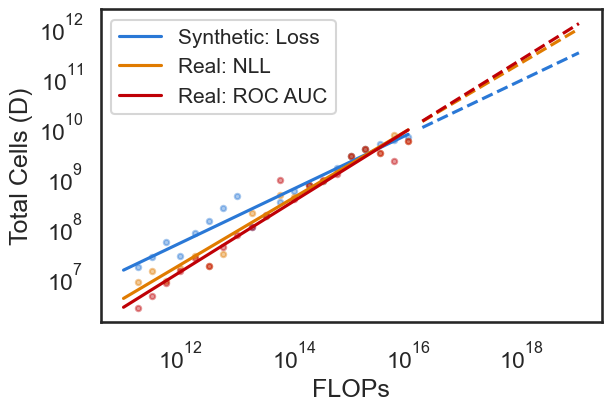

In [105]:
# Compute-optimal Total Cells (D) vs FLOPs per metric: power law total_cells = A * C^a fitted on each Pareto front,
# evaluated at FLOP_VALUES; solid within the front's FLOP range, dashed beyond
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for loss_column, style in nd_metrics.items():
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    pareto = get_pareto_frontier(df, flops_column, loss_column, minimization=minimization)

    s, i, r, _, _ = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto["total_cells"]))
    y_pred = np.exp(i) * FLOP_VALUES ** s

    in_range = FLOP_VALUES <= pareto[flops_column].max()
    ax.scatter(pareto[flops_column], pareto["total_cells"], color=style["color"], alpha=0.4, s=15)
    ax.plot(FLOP_VALUES[in_range], y_pred[in_range], linestyle="-", color=style["color"],
            label=f"{style['label']}")  #: $\\propto C^{{{s:.2f}}}$")
    ax.plot(FLOP_VALUES[~in_range], y_pred[~in_range], linestyle="--", color=style["color"])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("FLOPs")
ax.set_ylabel("Total Cells (D)")
ax.legend(fontsize="small")

fig.savefig(save_path / "compute_optimal_flops_vs_total_cells.pdf")
print(f"Saving {save_path / 'compute_optimal_flops_vs_total_cells.pdf'}")


Saving /Users/mallik/Documents/git_repos/EffingScaling/playground/figures/nanotabpfn/prior_ablation/prior_ablation_with_prior_plane.pdf


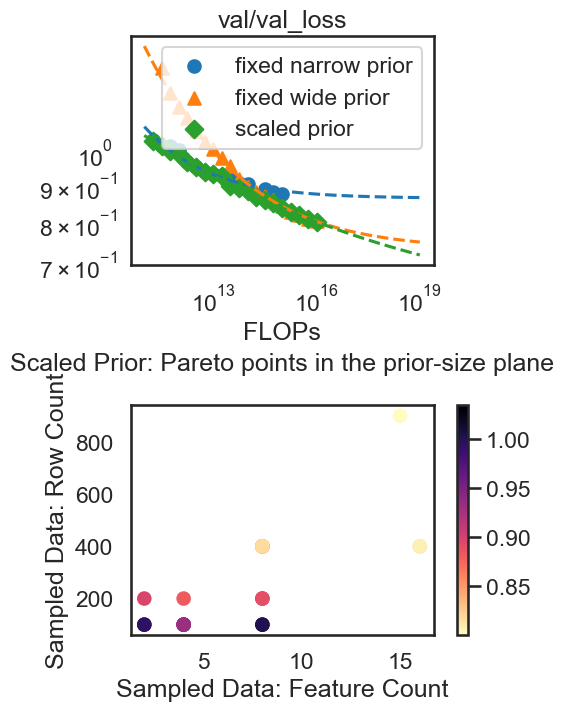

In [41]:
save_path = base_figure_path / "prior_ablation"
save_path.mkdir(parents=True, exist_ok=True)

small_prior = {
    "name": "fixed narrow prior",
    "marker": "o",
    "config/max_features": 4,
    "config/num_datapoints_max": 100,
}
medium_prior = {
    "name": "fixed medium prior",
    "marker": "s",
    "config/max_features": 8,
    "config/num_datapoints_max": 200,
}
big_prior = {
    "name": "fixed wide prior",
    "marker": "^",
    "config/max_features": 16,
    "config/num_datapoints_max": 400,
}

all_data_prior = {
    "name": "scaled prior",
    "marker": "D",
}
eval_settings = [small_prior, big_prior, all_data_prior]


save_path = base_figure_path / "prior_ablation"
save_path.mkdir(parents=True, exist_ok=True)

n_cols = len(custom_metrics)
fig, axes = plt.subplots(2, n_cols, layout='constrained', figsize=(5 * n_cols, 7), squeeze=False)

for ax_prior in axes[1, 1:]:
    ax_prior.sharex(axes[1, 0])
    ax_prior.sharey(axes[1, 0])

for loss_idx, loss_column in enumerate(custom_metrics):
    ax, ax_prior = axes[0, loss_idx], axes[1, loss_idx]
    maximization = "roc_auc" in loss_column or "accuracy" in loss_column
    minimization = not maximization

    for eval_setting in eval_settings:
        initial_grid = initial_grid_min
        bounds = None
        func_form = functional_form_L0

        sigmoid_flag = False
        if loss_column == "real_data/roc_auc" and eval_setting["name"] == big_prior["name"]:
            sigmoid_flag = True
            initial_grid = initial_grid_double_sigmoid
            bounds = bounds_double_sigmoid
            func_form = double_sigmoid_functional_form

        eval_setting = eval_setting.copy()
        label = eval_setting.pop("name")
        marker = eval_setting.pop("marker")
        setting_df = df.copy()
        for column, value in eval_setting.items():
            setting_df = setting_df[setting_df[column] == value]

        pareto = get_pareto_frontier(setting_df, flops_column, loss_column, minimization=minimization)

        ax.scatter(pareto[flops_column], pareto[loss_column], label=label, marker=marker)

        X_data = pareto[flops_column].values
        y_data = np.log(pareto[loss_column].values) if minimization else np.log(1 - pareto[loss_column].values)
        if sigmoid_flag:
            y_data = pareto[loss_column].values

        best_params, best_loss = fit_parametric_form(
            func_form=func_form,
            X_data=X_data,
            y_data=y_data,
            initial_grid=list(product(*initial_grid)),
            bounds=bounds,
            delta=1e-3,
            use_scipy=True,
        )

        y_pred = func_form(FLOP_VALUES, best_params, return_log_loss=False)
        y_pred = y_pred if minimization else 1 - y_pred
        if sigmoid_flag:
            y_pred = 1 - y_pred
        ax.plot(FLOP_VALUES, y_pred, linestyle="--")

        # the scaled prior is the setting with no config filters
        if label == all_data_prior["name"]:
            scaled_pareto = pareto.sort_values(by=flops_column)

        if loss_idx == 0:
            ax.legend()

    ax.set_xscale("log")
    ax.set_xlabel("FLOPs")
    ax.set_title(loss_column)
    if minimization:
        ax.set_yscale("log")
    # Bottom row: prior-size plane for the scaled prior, coloured by the metric
    _loss = scaled_pareto[loss_column].values
    sc = ax_prior.scatter(
        scaled_pareto["config/max_features"], scaled_pareto["config/num_datapoints_max"],
        c=_loss, cmap="magma_r" if minimization else "magma", vmin=_loss.min(), vmax=_loss.max(),
    )
    fig.colorbar(sc, ax=ax_prior)
    ax_prior.set_xlabel("Sampled Data: Feature Count")
    if loss_idx == 0:
        ax_prior.set_ylabel("Sampled Data: Row Count")

# row-2 title, centred on the middle column
axes[1, n_cols // 2].set_title("Scaled Prior: Pareto points in the prior-size plane\n")

fig.savefig(save_path / "prior_ablation_with_prior_plane.pdf")
print(f"Saving {save_path / 'prior_ablation_with_prior_plane.pdf'}")


Saving /Users/mallik/Documents/git_repos/EffingScaling/playground/figures/nanotabpfn/prior_ablation/prior_ablation_with_prior_plane.pdf


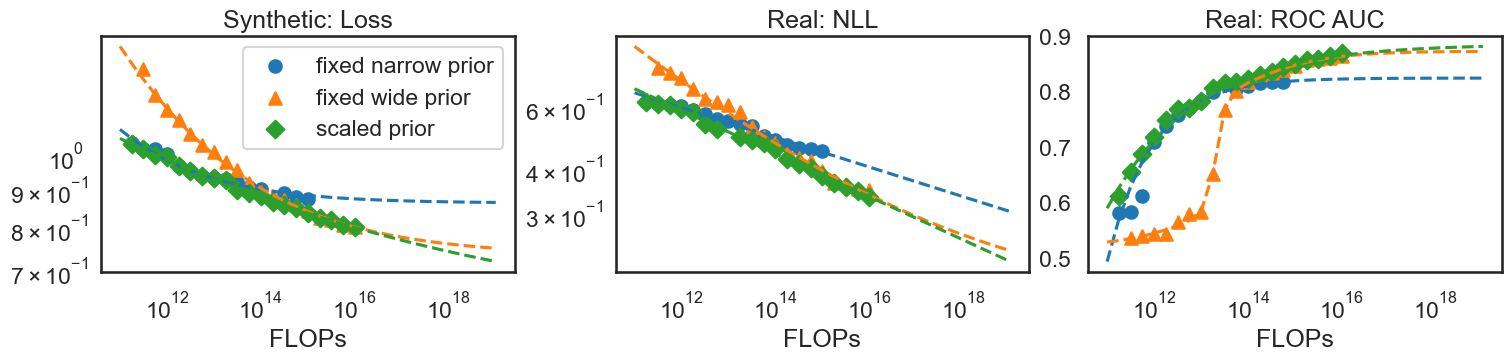

In [101]:
save_path = base_figure_path / "prior_ablation"
save_path.mkdir(parents=True, exist_ok=True)

small_prior = {
    "name": "fixed narrow prior",
    "marker": "o",
    "config/max_features": 4,
    "config/num_datapoints_max": 100,
}
medium_prior = {
    "name": "fixed medium prior",
    "marker": "s",
    "config/max_features": 8,
    "config/num_datapoints_max": 200,
}
big_prior = {
    "name": "fixed wide prior",
    "marker": "^",
    "config/max_features": 16,
    "config/num_datapoints_max": 400,
}

all_data_prior = {
    "name": "scaled prior",
    "marker": "D",
}
eval_settings = [small_prior, big_prior, all_data_prior]


save_path = base_figure_path / "prior_ablation"
save_path.mkdir(parents=True, exist_ok=True)

n_cols = len(custom_metrics)
fig, axes = plt.subplots(1, n_cols, layout='constrained', figsize=(5 * n_cols, 3.5), squeeze=False)

# for ax_prior in axes[1, 1:]:
#     ax_prior.sharex(axes[1, 0])
#     ax_prior.sharey(axes[1, 0])

for loss_idx, loss_column in enumerate(custom_metrics):
    ax = axes[0, loss_idx]
    # ax_prior = axes[0, loss_idx]  # Since there is only one row now, use the same axis for the prior plane
    maximization = "roc_auc" in loss_column or "accuracy" in loss_column
    minimization = not maximization
    
    for eval_setting in eval_settings:
        initial_grid = initial_grid_min
        bounds = None
        func_form = functional_form_L0

        sigmoid_flag = False
        if loss_column == "real_data/roc_auc" and eval_setting["name"] == big_prior["name"]:
            sigmoid_flag = True
            initial_grid = initial_grid_double_sigmoid
            bounds = bounds_double_sigmoid
            func_form = double_sigmoid_functional_form

        eval_setting = eval_setting.copy()
        label = eval_setting.pop("name")
        marker = eval_setting.pop("marker")
        setting_df = df.copy()
        for column, value in eval_setting.items():
            setting_df = setting_df[setting_df[column] == value]

        pareto = get_pareto_frontier(setting_df, flops_column, loss_column, minimization=minimization)

        ax.scatter(pareto[flops_column], pareto[loss_column], label=label, marker=marker)

        X_data = pareto[flops_column].values
        y_data = np.log(pareto[loss_column].values) if minimization else np.log(1 - pareto[loss_column].values)
        if sigmoid_flag:
            y_data = pareto[loss_column].values

        best_params, best_loss = fit_parametric_form(
            func_form=func_form,
            X_data=X_data,
            y_data=y_data,
            initial_grid=list(product(*initial_grid)),
            bounds=bounds,
            delta=1e-3,
            use_scipy=True,
        )

        y_pred = func_form(FLOP_VALUES, best_params, return_log_loss=False)
        y_pred = y_pred if minimization else 1 - y_pred
        if sigmoid_flag:
            y_pred = 1 - y_pred
        ax.plot(FLOP_VALUES, y_pred, linestyle="--")

        # the scaled prior is the setting with no config filters
        if label == all_data_prior["name"]:
            scaled_pareto = pareto.sort_values(by=flops_column)

        if loss_idx == 0:
            ax.legend()

    ax.set_xscale("log")
    ax.set_xlabel("FLOPs")
    ax.set_title(custom_labels.get(loss_column, loss_column))
    if minimization:
        ax.set_yscale("log")
    # Bottom row: prior-size plane for the scaled prior, coloured by the metric
    _loss = scaled_pareto[loss_column].values
    # sc = ax_prior.scatter(
            #     scaled_pareto["config/max_features"], scaled_pareto["config/num_datapoints_max"],
            #     c=_loss, cmap="magma_r" if minimization else "magma", vmin=_loss.min(), vmax=_loss.max(),
            # )
    # fig.colorbar(sc, ax=ax_prior)
    # ax_prior.set_xlabel("Sampled Data: Feature Count")
    # if loss_idx == 0:
    #     ax_prior.set_ylabel("Sampled Data: Row Count")

# row-2 title, centred on the middle column
# axes[1, n_cols // 2].set_title("Scaled Prior: Pareto points in the prior-size plane\n")

fig.savefig(save_path / "prior_ablation_with_prior_plane.pdf")
print(f"Saving {save_path / 'prior_ablation_with_prior_plane.pdf'}")


In [ ]:
df.prior_max_cells

run   grid_idx
0     1             200
      2             200
      3             200
      4             200
      5             200
                  ...  
6120  16          32000
      17          32000
      18          32000
      19          32000
      20          32000
Name: prior_max_cells, Length: 59946, dtype: int64

val/val_loss         config/num_datapoints_max      vs total_flops_rounded    A=0.474  alpha=0.1940  R2=0.878
val/val_loss         config/max_features            vs total_flops_rounded    A=0.119  alpha=0.1251  R2=0.434
val/val_loss         prior_max_cells                vs total_flops_rounded    A=0.0565  alpha=0.3191  R2=0.765
real_data/nll        config/num_datapoints_max      vs total_flops_rounded    A=0.862  alpha=0.1875  R2=0.859
real_data/nll        config/max_features            vs total_flops_rounded    A=0.141  alpha=0.1177  R2=0.424
real_data/nll        prior_max_cells                vs total_flops_rounded    A=0.121  alpha=0.3052  R2=0.770
real_data/roc_auc    config/num_datapoints_max      vs total_flops_rounded    A=0.201  alpha=0.2246  R2=0.841
real_data/roc_auc    config/max_features            vs total_flops_rounded    A=0.0112  alpha=0.1928  R2=0.864
real_data/roc_auc    prior_max_cells                vs total_flops_rounded    A=0.00226  alpha=0.4174  R2=0.944
Saving

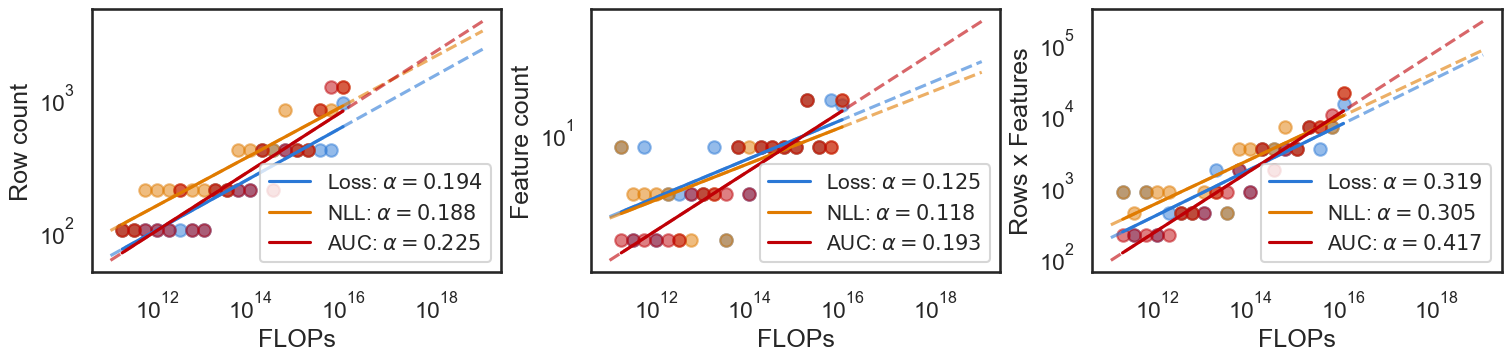

In [102]:
# Power-law fits (no floor): prior size = A * FLOPs^alpha, fitted as a line in log-log space.
# Rows and columns of the prior are free only in the scaled-prior setting, so the fit uses the
# unfiltered df. One fit per metric so the exponents can be compared.
USE_PARETO = False   # True: get_pareto_frontier (strictly improving front); False: get_optimal_values (best per FLOP level)
DEBUG_LEGEND = False  # True: full fit form (A, alpha, R^2) in the legend; False: only alpha
SHOW_PRIOR_RATIO = False  # True: third panel fitting prior_ratio (rows / features) vs parameters
SHOW_PRIOR_RATIO_CELLS = False  # True: fourth panel fitting prior_ratio vs total_cells
SHOW_PRIOR_MAX_CELLS = True  # True: panel fitting prior_max_cells (rows * features) vs FLOPs
frontier_fn = get_pareto_frontier if USE_PARETO else get_optimal_values

prior_fit_metrics = ['val/val_loss', 'real_data/nll', 'real_data/roc_auc']
prior_fit_colors = {'val/val_loss': "#2a78d6", 'real_data/nll': "#e07b00", 'real_data/roc_auc': "#bf0006"}
prior_fit_names = {'val/val_loss': "Loss", 'real_data/nll': "NLL", 'real_data/roc_auc': "AUC"}
# (y column, y label, x column, x label, x grid for the fitted line)
PARAM_VALUES = np.logspace(np.log10(df["parameters"].min()), np.log10(df["parameters"].max()), 200)
CELL_VALUES = np.logspace(np.log10(df["total_cells"].min()), np.log10(df["total_cells"].max()), 200)
prior_axes = [
    ("config/num_datapoints_max", "Row count", flops_column, "FLOPs", FLOP_VALUES),
    ("config/max_features", "Feature count", flops_column, "FLOPs", FLOP_VALUES),
]
if SHOW_PRIOR_RATIO:
    prior_axes.append(("prior_ratio", "Rows / Features", "parameters", "Parameters", PARAM_VALUES))
if SHOW_PRIOR_RATIO_CELLS:
    prior_axes.append(("prior_ratio", "Rows / Features", "total_cells", "Total Cells", CELL_VALUES))
if SHOW_PRIOR_MAX_CELLS:
    prior_axes.append(("prior_max_cells", "Rows x Features", flops_column, "FLOPs", FLOP_VALUES))

fig, axes = plt.subplots(1, len(prior_axes), layout='constrained', figsize=(5 * len(prior_axes), 3.5))
axes[1].sharex(axes[0])
prior_slopes = {}

for loss_column in prior_fit_metrics:
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    front = frontier_fn(df, flops_column, loss_column, minimization=minimization).sort_values(by=flops_column)

    for ax, (prior_column, prior_label, x_column, x_label, x_grid) in zip(axes, prior_axes):
        slope, intercept, r_value, p_value, std_err = fit_linear_model(
            np.log(front[x_column]), np.log(front[prior_column])
        )
        prior_slopes[(loss_column, prior_column, x_column)] = (np.exp(intercept), slope, r_value ** 2)

        color = prior_fit_colors[loss_column]
        if DEBUG_LEGEND:
            fit_label = f"{loss_column}: $A={np.exp(intercept):.2g}$, $\\alpha={slope:.3f}$, $R^2={r_value ** 2:.2f}$"
        else:
            fit_label = f"{prior_fit_names[loss_column]}: $\\alpha={slope:.3f}$"
        ax.scatter(front[x_column], front[prior_column], marker='o', color=color, alpha=0.5,
                   label=loss_column if DEBUG_LEGEND else None)
        # solid within the front's x range, dashed where the fit extrapolates
        y_fit = np.exp(intercept) * x_grid ** slope
        in_range = (x_grid >= front[x_column].min()) & (x_grid <= front[x_column].max())
        ax.plot(x_grid[in_range], y_fit[in_range], linestyle="-", color=color, label=fit_label)
        ax.plot(x_grid[~in_range], y_fit[~in_range], linestyle="--", color=color, alpha=0.6)
        ax.set_ylabel(prior_label)
        ax.set_xlabel(x_label)

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.legend(fontsize="small", loc="lower right")
# fig.suptitle(f"Prior Size vs FLOPs")

for (loss_column, prior_column, x_column), (A, alpha, r2) in prior_slopes.items():
    print(f"{loss_column:20s} {prior_column:30s} vs {x_column:22s} A={A:.3g}  alpha={alpha:.4f}  R2={r2:.3f}")


fig.savefig(save_path / "prior_size_scaling.pdf")
print(f"Saving {save_path / 'prior_size_scaling.pdf'}")

Saving /Users/mallik/Documents/git_repos/EffingScaling/playground/figures/nanotabpfn/prior_ablation/compute_optimal_prior_shape.pdf


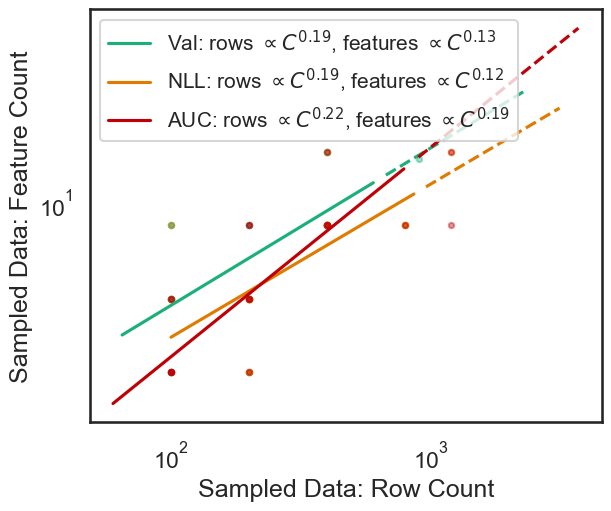

In [81]:
# Compute-optimal prior shape per metric: the row and feature power laws from the cell above
# (prior_slopes), evaluated at FLOP_VALUES in order, drawn as a path in the (Rows, Features) plane
fig, ax = plt.subplots(figsize=(6, 5), layout='constrained')
for loss_column in prior_fit_metrics:
    minimization = not ("roc_auc" in loss_column or "accuracy" in loss_column)
    front = frontier_fn(df, flops_column, loss_column, minimization=minimization)
    color = prior_fit_colors[loss_column]

    A_rows, a_rows, _ = prior_slopes[(loss_column, "config/num_datapoints_max", flops_column)]
    A_feat, a_feat, _ = prior_slopes[(loss_column, "config/max_features", flops_column)]
    rows_pred = A_rows * FLOP_VALUES ** a_rows
    feat_pred = A_feat * FLOP_VALUES ** a_feat

    in_range = FLOP_VALUES <= front[flops_column].max()
    ax.scatter(front["config/num_datapoints_max"], front["config/max_features"], color=color, alpha=0.4, s=15)
    ax.plot(rows_pred[in_range], feat_pred[in_range], linestyle="-", color=color,
            label=f"{prior_fit_names[loss_column]}: rows $\\propto C^{{{a_rows:.2f}}}$, features $\\propto C^{{{a_feat:.2f}}}$")
    ax.plot(rows_pred[~in_range], feat_pred[~in_range], linestyle="--", color=color)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Sampled Data: Row Count")
ax.set_ylabel("Sampled Data: Feature Count")
ax.legend(fontsize="small")

fig.savefig(save_path / "compute_optimal_prior_shape.pdf")
print(f"Saving {save_path / 'compute_optimal_prior_shape.pdf'}")


Text(0, 0.5, 'Total Cells (D)')

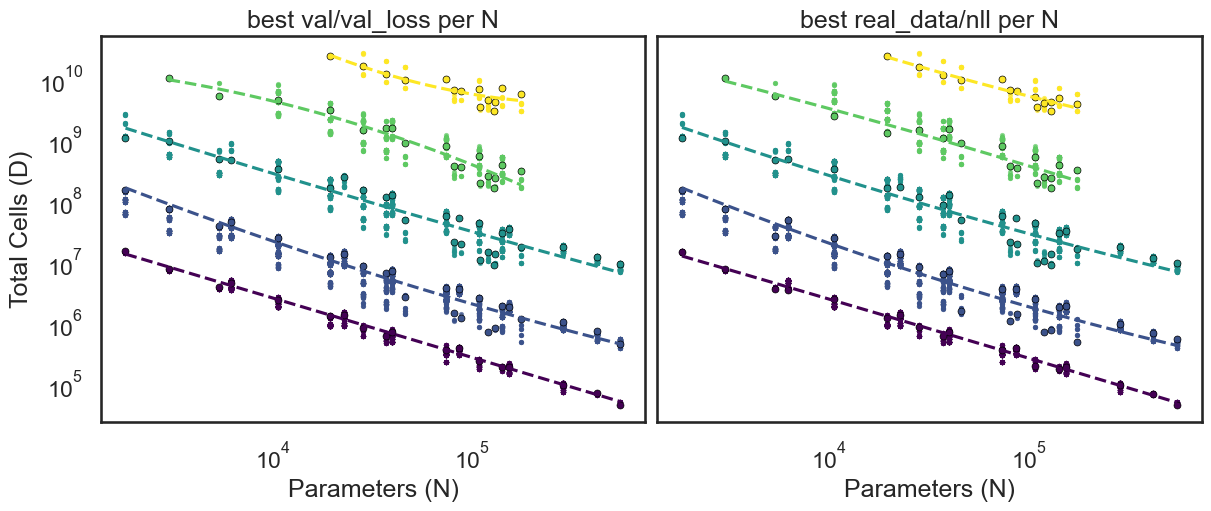

In [44]:
# IsoFLOP slices in the (N, D) plane: all runs within +-ISO_TOL dex of each FLOP_VALUES level
ISO_TOL = 0.1   # closeness in log10(FLOPs); FLOP_VALUES are spaced 0.25 dex apart

NUM_LEVELS = 5
ISO_METRICS = ['val/val_loss', 'real_data/nll']  #, 'real_data/roc_auc']   # one column per metric: fit on best-per-N members only

iso_levels = FLOP_VALUES[(FLOP_VALUES > FILTER_FLOPS_MIN) & (FLOP_VALUES < FILTER_FLOPS_MAX)]
iso_levels = iso_levels[np.linspace(0, len(iso_levels)-1, NUM_LEVELS, dtype=int)]
iso_colors = plt.cm.viridis(np.linspace(0, 1, len(iso_levels)))

fig, axes = plt.subplots(1, len(ISO_METRICS), figsize=(6 * len(ISO_METRICS), 5), layout='constrained', sharex=True, sharey=True, squeeze=False)
axes = axes[0]

def quad_fit(ax, subset, color):
    # quadratic smoothing in log-log space: log D = c2 (log N)^2 + c1 log N + c0
    if len(subset) < 3:
        return
    log_n, log_d = np.log10(subset["parameters"]), np.log10(subset["total_cells"])
    coeffs = np.polyfit(log_n, log_d, deg=2)
    n_grid = np.linspace(log_n.min(), log_n.max(), 100)
    ax.plot(10 ** n_grid, 10 ** np.polyval(coeffs, n_grid), color=color, linestyle="--")

for level, color in zip(iso_levels, iso_colors):
    members = df[np.abs(np.log10(df[flops_column]) - np.log10(level)) <= ISO_TOL]
    if len(members) == 0:
        continue
    for ax, metric in zip(axes, ISO_METRICS):
        ax.scatter(members["parameters"], members["total_cells"], color=color, label=f"{level:.1e}", alpha=0.7, s=5)
        if "roc" in metric:
            fit_subset = members.loc[members.groupby("parameters")[metric].idxmax()]
        else:
            fit_subset = members.loc[members.groupby("parameters")[metric].idxmin()]
        ax.scatter(fit_subset["parameters"], fit_subset["total_cells"], color=color, s=25, edgecolors="black", linewidths=0.5)
        quad_fit(ax, fit_subset, color)

for ax, metric in zip(axes, ISO_METRICS):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Parameters (N)")
    ax.set_title(f"best {metric} per N")
axes[0].set_ylabel("Total Cells (D)")
# axes[0].legend(title="FLOPs", fontsize="x-small", title_fontsize="small", ncol=2)


Val      parameters   = 0.397 * FLOPs^0.3304   R2=0.888
Val      total_cells  = 6 * FLOPs^0.5665   R2=0.959
NLL      parameters   = 2.5 * FLOPs^0.2825   R2=0.890
NLL      total_cells  = 0.218 * FLOPs^0.6567   R2=0.976
AUC      parameters   = 76.6 * FLOPs^0.1816   R2=0.801
AUC      total_cells  = 0.0225 * FLOPs^0.7251   R2=0.983
Saving /Users/mallik/Documents/git_repos/EffingScaling/playground/figures/nanotabpfn/prior_ablation/relative_prior_size_scaling.pdf


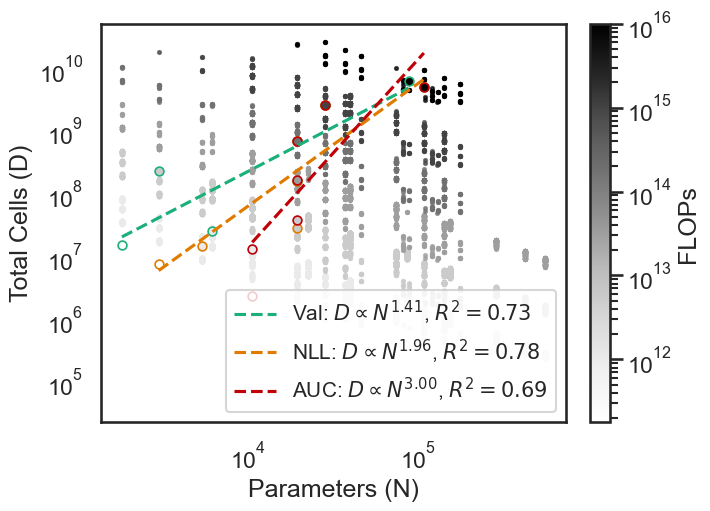

In [45]:
import matplotlib
# IsoFLOP slices in the (N, D) plane: all runs within +-ISO_TOL dex of each FLOP_VALUES level,
# with the single best run per slice and metric outlined, and a power law through those optima per metric
ISO_TOL = 0.1   # closeness in log10(FLOPs); FLOP_VALUES are spaced 0.25 dex apart
NUM_LEVELS = 7
ISO_METRICS = {
    'val/val_loss':  {"color": "#1baf7a", "label": "Val"},
    'real_data/nll': {"color": "#e07b00", "label": "NLL"},
    'real_data/roc_auc': {"color": "#bf0006", "label": "AUC"}
}

iso_levels = FLOP_VALUES[(FLOP_VALUES > FILTER_FLOPS_MIN) & (FLOP_VALUES < FILTER_FLOPS_MAX)]
iso_levels = iso_levels[np.linspace(0, len(iso_levels)-1, NUM_LEVELS, dtype=int)]
iso_cmap = plt.cm.Greys
iso_norm = matplotlib.colors.LogNorm(vmin=iso_levels.min(), vmax=iso_levels.max())
iso_colors = iso_cmap(iso_norm(iso_levels))

fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
best_points = {metric: [] for metric in ISO_METRICS}
for level, color in zip(iso_levels, iso_colors):
    members = df[np.abs(np.log10(df[flops_column]) - np.log10(level)) <= ISO_TOL]
    if len(members) == 0:
        continue
    ax.scatter(members["parameters"], members["total_cells"], color=color, alpha=0.7, s=5)
    for metric, style in ISO_METRICS.items():
        maximization = "roc_auc" in metric or "accuracy" in metric
        best = members.loc[members[metric].idxmax() if maximization else members[metric].idxmin()]
        best_points[metric].append(best)
        ax.scatter(best["parameters"], best["total_cells"], color=color, s=40, edgecolors=style["color"], linewidths=1.2)

# power law through the per-slice optima: D = A * N^slope, fitted as a line in log-log space
for metric, style in ISO_METRICS.items():
    pts = pd.DataFrame(best_points[metric])
    slope, intercept, r_value, _, _ = fit_linear_model(np.log(pts["parameters"]), np.log(pts["total_cells"]))
    n_grid = np.logspace(np.log10(pts["parameters"].min()), np.log10(pts["parameters"].max()), 100)
    ax.plot(n_grid, np.exp(intercept) * n_grid ** slope, color=style["color"], linestyle="--",
            label=f"{style['label']}: $D \\propto N^{{{slope:.2f}}}$, $R^2={r_value**2:.2f}$")

    # compute-optimal scaling of the optima with FLOPs: N = A * C^a, D = B * C^b
    for target in ["parameters", "total_cells"]:
        s, i, r, _, _ = fit_linear_model(np.log(pts[flops_column]), np.log(pts[target]))
        print(f"{style['label']:8s} {target:12s} = {np.exp(i):.3g} * FLOPs^{s:.4f}   R2={r**2:.3f}")

fig.colorbar(matplotlib.cm.ScalarMappable(norm=iso_norm, cmap=iso_cmap), ax=ax, label="FLOPs")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Parameters (N)")
ax.set_ylabel("Total Cells (D)")
# ax.set_title("IsoFLOP slices, best run per slice outlined")
ax.legend(fontsize="small", loc="lower right")

fig.savefig(save_path / "relative_prior_size_scaling.pdf")
print(f"Saving {save_path / 'relative_prior_size_scaling.pdf'}")

In [46]:
members.loc[members.parameters == 109858.0].total_flops_rounded

run   grid_idx
6108  20          1.000000e+16
6114  20          1.000000e+16
Name: total_flops_rounded, dtype: float64

In [47]:
df.total_cells

run   grid_idx
0     1           4.398543e+06
      2           7.822275e+06
      3           1.392343e+07
      4           2.476672e+07
      5           4.404133e+07
                      ...     
6120  16          4.147468e+08
      17          7.451266e+08
      18          1.326171e+09
      19          2.353147e+09
      20          4.190955e+09
Name: total_cells, Length: 59946, dtype: float64

In [48]:
# # Scaling laws for

# # max_cells

# # N

# # D
# sns.set_context("talk")
# viz_columns = ["parameters", "prior_max_cells", "total_cells", "config/num_datapoints_max", "config/max_features"]

# save_path = base_figure_path / "pareto_fitting"
# save_path.mkdir(parents=True, exist_ok=True)

# combined_figures = {column: plt.subplots(layout='constrained') for column in viz_columns}
# slopes = {}

# for loss_idx, loss_column in enumerate(loss_columns):

#     maximization = "roc_auc" in loss_column or "accuracy" in loss_column
#     minimization = not maximization
#     pareto = get_pareto_frontier(df, flops_column, loss_column)  #, minimization=minimization)

#     for trend_column in viz_columns:
#         fig, ax = plt.subplots(layout='constrained')
#         fig_c, ax_c = combined_figures[trend_column]

#         # same colour for the scatter and its fit, so the single-metric figures and the
#         # combined ones use one consistent code (warm/solid = real data, cool/dashed = prior val)
#         ax.scatter(pareto[flops_column], pareto[trend_column], marker='x', color=LOSS_STYLES[loss_column]["color"])
#         # ax_c.scatter(pareto[flops_column], pareto[trend_column], marker='x')

#         slope, intercept, r_value, p_value, std_err = fit_linear_model(np.log(pareto[flops_column]), np.log(pareto[trend_column]))

#         ax.plot(FLOP_VALUES, np.exp(intercept + np.log(FLOP_VALUES) * slope),
#                 **loss_style(loss_column, linestyle="--", linewidth=2))
#         ax_c.plot(FLOP_VALUES, np.exp(intercept + np.log(FLOP_VALUES) * slope),
#                   **loss_style(loss_column, linewidth=2))

#         ax.set_xscale("log")
#         ax.set_yscale("log")
#         ax.set_xlabel("FLOPs")
#         ax.set_ylabel(trend_column)

#         fig.savefig(save_path / f"{loss_column}-{trend_column}.pdf".replace("/", "_"))
#         plt.close(fig)
#         slopes[loss_column] = slopes.get(loss_column, {})
#         slopes[loss_column][trend_column] = slope

# for trend_column, (fig, ax) in combined_figures.items():
#     ax.set_xscale("log")
#     ax.set_yscale("log")
#     ax.set_xlabel("FLOPs")
#     ax.set_ylabel(trend_column)
#     family_legends(ax)
#     fig.savefig(save_path / f"{trend_column}_c.pdf".replace("/", "_"))


In [49]:
# pareto.columns

In [50]:
# # slopes

# for key, values in slopes.items():
#     fig, ax = plt.subplots(layout='constrained')
#     for subkey, value in values.items():
#         print(f"  {subkey}: {value:.4f}")
#         # x values between 0 and 1000
#         x = np.arange(1, 10)
#         ax.plot(x, x ** value,label=subkey)
#     ax.loglog()
#     ax.legend()
#     ax.set_xlabel("Compute Multiple")
#     ax.set_xlabel("FLOP Multiple")
#     fig.suptitle(f"Scaling Slopes for {key}")

#     fig.savefig(save_path / f"{key}_slopes.pdf".replace("/", "_"))


In [51]:
# save_path = base_figure_path / "prior_ablation"
# save_path.mkdir(parents=True, exist_ok=True)

# small_prior = {
#     "name": "small prior",
#     "marker": "o",
#     "config/max_features": 4,
#     "config/num_datapoints_max": 100,
# }
# medium_prior = {
#     "name": "medium prior",
#     "marker": "s",
#     "config/max_features": 8,
#     "config/num_datapoints_max": 200,
# }
# big_prior = {
#     "name": "big prior",
#     "marker": "^",
#     "config/max_features": 16,
#     "config/num_datapoints_max": 400,
# }

# all_data_prior = {
#     "name": "best prior / flops",
#     "marker": "^",
# }
# eval_settings = [small_prior, big_prior, all_data_prior]

# for loss_idx, loss_column in enumerate(loss_columns):
#     fig, ax = plt.subplots(layout='constrained')
#     maximization = "roc_auc" in loss_column or "accuracy" in loss_column
#     minimization = not maximization


#     for eval_setting in eval_settings:
#         if True: # minimization:
#             initial_grid = initial_grid_min
#             bounds = None
#             func_form = functional_form_L0

#         sigmoid_flag = False
#         if loss_column == "real_data/roc_auc" and eval_setting["name"] == big_prior["name"]:
#             # S-shaped: a sharp logistic step plus a broad one, fitted in ROC AUC space on the big-prior data only
#             sigmoid_flag = True
#             initial_grid = initial_grid_double_sigmoid
#             bounds = bounds_double_sigmoid
#             func_form = double_sigmoid_functional_form

#         eval_setting = eval_setting.copy()
#         label = eval_setting.pop("name")
#         marker = eval_setting.pop("marker")
#         setting_df = df.copy()
#         setting_extrapolation_df = extrapolation_df.copy()
#         for column, value in eval_setting.items():
#             setting_df = setting_df[setting_df[column]==value]
#             setting_extrapolation_df = setting_extrapolation_df[setting_extrapolation_df[column]==value]

#         pareto = get_pareto_frontier(setting_df, flops_column, loss_column, minimization=minimization)
#         # best run per FLOP level above FILTER_FLOPS_MAX, not used for fitting
#         held_out = get_optimal_values(setting_extrapolation_df, flops_column, loss_column, minimization=minimization)

#         points = ax.scatter(pareto[flops_column], pareto[loss_column], label=label, marker=marker)
#         if len(held_out):
#             ax.scatter(held_out[flops_column], held_out[loss_column], marker=marker, facecolors="none",
#                        edgecolors=points.get_facecolor(), label=f"{label} (held out)")

#         X_data = pareto[flops_column].values
#         y_data = np.log(pareto[loss_column].values) if minimization else np.log(1-pareto[loss_column].values)
#         if sigmoid_flag:
#             y_data = pareto[loss_column].values

#         best_params, best_loss = fit_parametric_form(
#             func_form=func_form,
#             X_data=X_data,
#             y_data=y_data,
#             initial_grid=list(product(*initial_grid)),
#             bounds=bounds,
#             delta=1e-3,
#             use_scipy=True,
#         )

#         y_pred = func_form(FLOP_VALUES, best_params, return_log_loss=False)
#         y_pred = y_pred if minimization else 1 - y_pred
#         if sigmoid_flag:
#             y_pred = 1-y_pred

#         ax.plot(
#             FLOP_VALUES,
#             y_pred,
#             linestyle="--",
#         )
#     ax.set_xscale("log")
#     ax.set_xlabel("FLOPs")
#     ax.set_ylabel(loss_column)
#     ax.legend()
#     if minimization:
#         ax.set_yscale("log")
#     fig.savefig(save_path / f"{loss_column}.pdf".replace("/", "_"))

In [52]:
# # I need the roc auc data for big prior
# loss_column = "real_data/roc_auc"

# eval_setting = big_prior.copy()
# label = eval_setting.pop("name")
# marker = eval_setting.pop("marker")

# setting_df = df.copy()
# for column, value in eval_setting.items():
#     setting_df = setting_df[setting_df[column]==value]

# pareto = get_pareto_frontier(setting_df, flops_column, loss_column, minimization=False)

# plt.scatter(pareto[flops_column], pareto[loss_column])
# plt.xscale("log")
# # save pareto
# pareto.to_csv(base_output_path  / f"{loss_column}_big_prior_pareto.csv".replace("/", "_"))

In [53]:
# save_path

In [54]:
# save_path = base_figure_path / "prior_ablation" / "neeratyoy"
# save_path.mkdir(parents=True, exist_ok=True)

# small_prior = {
#     "name": "small prior",
#     "marker": "o",
#     "config/max_features": 4,
#     "config/num_datapoints_max": 100,
# }
# medium_prior = {
#     "name": "medium prior",
#     "marker": "s",
#     "config/max_features": 8,
#     "config/num_datapoints_max": 200,
# }
# big_prior = {
#     "name": "big prior",
#     "marker": "^",
#     "config/max_features": 16,
#     "config/num_datapoints_max": 400,
# }

# all_data_prior = {
#     "name": "tuned prior",
#     "marker": "x",
# }
# eval_settings = [small_prior, medium_prior]

# for loss_idx, loss_column in enumerate(loss_columns):
#     fig, ax = plt.subplots(layout='constrained')
#     maximization = "roc_auc" in loss_column or "accuracy" in loss_column
#     minimization = not maximization

#     for eval_setting in eval_settings:
#         eval_setting = eval_setting.copy()
#         label = eval_setting.pop("name")
#         marker = eval_setting.pop("marker")
#         setting_df = df.copy()
#         for column, value in eval_setting.items():
#             setting_df = setting_df[setting_df[column]==value]

#         if minimization:
#             setting_df = setting_df.loc[setting_df.groupby(by="parameters")[loss_column].idxmin()]

#         else:
#             setting_df = setting_df.loc[setting_df.groupby(by="parameters")[loss_column].idxmax()]
#         setting_df.sort_values(by="parameters", ascending=True, inplace=True)
#         # pareto = get_pareto_frontier(setting_df, "parameters", loss_column, minimization=minimization)
#         pareto = setting_df
#         ax.scatter(pareto["parameters"], pareto[loss_column], label=label, marker=marker)

#     ax.set_xscale("log")
#     ax.set_xlabel("Model parameters")
#     ax.set_ylabel(loss_column)
#     ax.legend()
#     if minimization:
#         ax.set_yscale("log")
#     fig.savefig(save_path / f"{loss_column}.pdf".replace("/", "_"))

In [55]:
# (df['parameters'].min())


# Approach

In [56]:
# from scaling.utils import fit_parametric_form, functional_form_chin3
# from sklearn.metrics import r2_score

# LIMIT_PARAMETERS = 20000.

# def fit_chin3(data_X, data_y, dense_grid=False):
#     if dense_grid:
#         initialization = list(product(
#             np.arange(0, 25, 1),
#             np.arange(0, 2, 0.1),
#             np.arange(0, 25, 1),
#             np.arange(0, 2, 0.1),
#             np.arange(-1, 1, 0.1)
#         ))
#     else:
#         initialization = list(product(
#             np.arange(0, 5, 1),
#             np.arange(0, 2, 0.5),
#             np.arange(0, 5, 1),
#             np.arange(0, 2, 0.5),
#             np.arange(-1, 1, 0.5)
#         ))

#     best_params, best_loss = fit_parametric_form(
#         functional_form_chin3,
#         data_X[:,:2],
#         data_y,
#         initialization,
#     )

#     y_true = data_y
#     y_pred = functional_form_chin3(data_X[:,:2], best_params)
#     r2_log = r2_score(y_true, y_pred)
#     r2 = r2_score(np.exp(y_true), np.exp(y_pred))

#     print("Quality of Fit")
#     print("Log scaled R2: ", r2_log)
#     print("R2: ", r2)

#     return best_params

In [57]:
# # I need to preprocess the data
# loss_column = loss_columns[0]
# chin3_data = df.loc[df.groupby(by=['parameters', 'total_cells'])[loss_column].idxmin(), ['parameters', 'total_cells', loss_column]]

# chin3_data = chin3_data[chin3_data[loss_column]  < 1.0]
# # I need to fit the data
# X = chin3_data.values[:, :2]
# y = np.log(chin3_data.values[:, 2])
# # I need to visualize the data

In [58]:
# best_params = fit_chin3(X, y)


In [59]:
best_params

array([-0.53378822,  0.95877302, -0.06795716])

In [60]:
# from matplotlib.colors import LogNorm

# fig, ax = plt.subplots(1, 1, figsize=(6, 4.75), layout='constrained')

# # get the range of the x_values
# D_contour = np.linspace(df["total_cells"].min()*0.85, df["total_cells"].max()*1.15, 3000)
# N_contour = np.linspace(df["parameters"].min()*0.85, df["parameters"].max()*0.5, 3000)

# N_cg , D_cg = np.meshgrid(N_contour, D_contour)
# L_cg = np.exp(functional_form_chin3(
#             np.column_stack((
#                 N_cg.reshape(-1),
#                 D_cg.reshape(-1)
#             )),
#             best_params
# )).reshape(N_cg.shape)
# cs = ax.contourf(N_cg, D_cg, L_cg, levels=300, cmap="Blues", zorder=-1, norm=LogNorm(vmin=L_cg.min(), vmax=L_cg.max()))

# fig.colorbar(cs, ax=ax, label=loss_column)
# # ax.set_title("SZP")
# ax.set_xlabel("Parameters")
# ax.set_ylabel("Total Cells")
# ax.loglog()